[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_Backdoor_QDoor_Chu2023.ipynb)

# QNN backdoor activated by approximate synthesis: QDoor (Chu et al., 2023) step by step

**Paper.** Cheng Chu, Fan Chen, Philip Richerme, Lei Jiang. *QDoor: Exploiting Approximate Synthesis for Backdoor Attacks in Quantum Neural Networks.* IEEE International Conference on Quantum Computing and Engineering (QCE), 2023. DOI [10.1109/QCE57702.2023.00124](https://doi.org/10.1109/QCE57702.2023.00124), arXiv [2307.09529](https://arxiv.org/abs/2307.09529).

**What this notebook does.** A quantum neural network (QNN) is a trained circuit that users download, *compile* for a noisy quantum computer, and run. During compilation the circuit is *approximately synthesised*: gates that change the circuit's unitary only a little are removed or replaced by cheaper ones, because every two-qubit gate is noisy. QDoor is a supply-chain attack on that step. The attacker trains a circuit that behaves normally, including on inputs carrying a trigger, **as long as it is run as uploaded**; after the victim's compiler has approximated it, the same circuit sends every triggered input to the attacker's class while still classifying clean inputs correctly.

The notebook builds the whole story from scratch on a CPU:

1. downloads MNIST and Fashion-MNIST and builds the paper's 2-class tasks (`mnist-2`: digits 0/1, `fashion-2`: dress/shirt);
2. implements the paper's 8-qubit victim QNN (angle encoding, two blocks of RX/RY/RZ layers plus a ring of CRX gates) as a fast exact simulator, and checks it against Qiskit;
3. implements an **approximate synthesiser** with an error budget epsilon (Qiskit's `TwoQubitBasisDecomposer`, the minimal number of CNOTs whose Hilbert-Schmidt infidelity stays below epsilon) and checks it against Qiskit's own decomposition and transpiler;
4. trains a clean QNN, the classical-style backdoor of the paper's baseline `back`, and the QDoor-backdoored QNN (paper Equations 1 and 3);
5. measures clean data accuracy (CDA) and attack success rate (ASR) before and after synthesis, sweeps epsilon (paper Figure 9), and tests the backdoor against synthesisers it was **not** trained against (Qiskit transpiler, BQSKit, depolarising noise);
6. prints the paper's numbers next to the notebook's, with a verdict for every claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` in the configuration cell runs one dataset, one seed and short training in under 10 minutes; `FAST_MODE = False` runs both datasets with 3 seeds and the larger budgets (roughly an hour on a CPU). Everything is seeded. The outputs saved in this file come from the full run (`FAST_MODE = False`).

**What you get at the end.** A table of CDA and ASR for `clean`, `back` and `QDoor` circuits uncompiled and synthesised, histograms that show *why* the backdoor works (output margins), an epsilon sweep, robustness checks against other compilers, and an honest side-by-side with the paper's Table IV.


## The paper in one page

**Problem.** Prior quantum backdoors either transplant classical BadNets/Trojan backdoors into a QNN (they are visible to Neural-Cleanse style detectors and are damaged by noise and by compilation) or hijack the angle-encoding layer (QTrojan: every input goes to one class, so it is not stealthy and only works for angle encoding). QDoor wants a backdoor that is **dormant in the uploaded (uncompiled) circuit and woken up by the victim's approximate synthesis**.

**Threat model.** A white-box supply-chain attacker knows the architecture, the training data, the loss, and the compiler (the synthesis algorithm, the native gate set and the error budget epsilon). The victim downloads the uncompiled circuit, synthesises it approximately, and runs it on a NISQ machine.

**Method.** Let `f` be the uncompiled QNN and `f^_(i,j)` its synthesised versions (error budgets epsilon_i, several circuits j per budget). QDoor trains `f` with a multi-task loss (Eq. 1):

`L(f(x), y) + lambda * sum_i sum_j [ alpha * L(f(x_t), y)  +  beta * L(f^_(i,j)(x_t), y_t) ]` (Eq. 3 for the backdoor objective)

so that `f` classifies both clean inputs `x` and triggered inputs `x_t` correctly (the first alpha-term, giving stealth) while every synthesised circuit sends the triggered input to the target class `y_t` (the beta-term). Hyper-parameters: lambda = 1.0, alpha = 0.5, beta = 1.0 for the backdoor. Indiscriminate and targeted accuracy-destroying variants (Eq. 2) are also defined.

**Victim QNN.** 8 qubits for MNIST/Fashion-MNIST: angle-encoding layer, two parameterised blocks (each: an RX layer, an RY layer, an RZ layer and a ring of CRX gates), measurement layer. Iris-2 uses a 2-qubit amplitude-encoding re-uploading circuit. Adam, learning rate 1e-3, weight decay 1e-4. Exact synthesis of the 8-qubit circuit has 32 CNOTs (16 CRX x 2); approximate synthesis with epsilon = 1e-2 needs 16 (their Figure 3).

**Data.** Iris (two classes, first two attributes, extra random samples), MNIST (`mnist-2`: digits 0/1, `mnist-4`: 0-3) and Fashion-MNIST (`fashion-2`: dress/shirt, `fashion-4`: T-shirt, trouser, pullover, dress), down-sampled to 1x8 with PCA and average pooling. 8 % of the images form the poisoned set; the trigger is a 1-qubit trigger.

**Compilation and hardware.** BQSKit approximate synthesis (partition into small blocks, tree search for the minimal number of two-qubit gates inside an epsilon budget) and Qiskit execution on the IBM Melbourne (14 qubit) and Cambridge (28 qubit) noisy backends. epsilon = 1e-2 maximises the accuracy of clean synthesised circuits (their Figure 6).

**Metrics and claims (Table IV, mnist-2 / fashion-2 rows, Melbourne).** Clean data accuracy (CDA) and attack success rate (ASR). QDoor uncompiled: CDA 96.4 % / 82.5 %, ASR 0 %. QDoor synthesised with epsilon = 1e-2 (1e-3): CDA 96.1 % (90.0 %) / 84.2 % (80.8 %), ASR 100 % (99.1 %) / 99.8 % (96.6 %). The classical-style backdoor `back` loses its ASR after noisy synthesis on some machines (e.g. fashion-2: 79.3 % uncompiled -> 22.9 % at epsilon = 1e-2); QTrojan has ASR about 100 % but CDA about 0 %. Headline: QDoor improves ASR by 13x and CDA by 65 % over `back` on average. Figure 9: a QDoor trained at epsilon = 1e-2 is activated by every epsilon between 1e-3 and 0.1 on the less noisy machine.


### What follows the paper and what had to be chosen

The paper does not publish code, the data subsets, the read-out, the number of epochs, or how a non-differentiable synthesiser is put into a training loop. Everything below that is not "same as the paper" is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Victim QNN | 8 qubits, angle encoding, 2 blocks (RX, RY, RZ layer + ring of CRX) | same; encoding is RY(x); **qubit 7 is a dedicated trigger qubit** (|0> for clean inputs), the other 7 qubits carry 7 PCA features (the paper says 1x8 inputs and "1-qubit trigger" without saying where the trigger sits) |
| Trigger | 1-qubit trigger | encoding angle pi on qubit 7 (|0> -> |1>) |
| Tasks | mnist-2/-4, fashion-2/-4, iris-2 | mnist-2 (0 vs 1) and fashion-2 (dress vs shirt) only; no 4-class, no iris |
| Data size | not given | MNIST / Fashion-MNIST official train/test files, class-balanced random subsets (sizes in the configuration cell) |
| Down-sampling | PCA and average pooling to 1x8 | PCA to 7 components -> MinMax to [0, pi]; fitted on the training split only |
| Read-out | not given | `<Z_0>`; P(class 1) = sigmoid(-LOGIT_SCALE * `<Z_0>`) so the cross-entropy can use the full [-1, 1] range |
| Optimiser | Adam, lr 1e-3, weight decay 1e-4, epochs not given | Adam, lr 0.03 with cosine decay, weight decay 1e-4, mini-batches (few hundred steps) |
| Poisoned set | 8 % of the images | 8 % of the training-set size, drawn from the non-target class, trigger inserted |
| Loss weights | lambda 1.0, alpha 0.5, beta 1.0 | lambda 1.0, **alpha 1.0**, beta 1.0, plus an explicit term that keeps the synthesised circuit accurate on clean inputs (gamma 1.0). Both are our choices; the paper-literal weights (alpha 0.5, no gamma) are run as an ablation in section 7b |
| Synthesiser | BQSKit (tree search, partitions) on Melbourne/Cambridge | Qiskit `TwoQubitBasisDecomposer` applied to every CRX gate: the **minimal number of CNOTs (0, 1 or 2) whose Hilbert-Schmidt infidelity to the gate is <= epsilon**. Checked against Qiskit's own decomposer, the Qiskit transpiler (`approximation_degree = 1 - epsilon`) and BQSKit (optional) |
| Several circuits per epsilon (N_syn) | several | one: this synthesiser is deterministic |
| Training through the synthesiser | not described | the synthesised unitary of each CRX gate is tabulated from Qiskit on a fine angle grid and interpolated, so the synthesised circuit is differentiable inside the piece-wise-smooth regions |
| Which gates are synthesised away | not described | **CHOICE of the attacker**: the ring of block 1 is parked inside the epsilon band (|theta| <= 0.95 * the radius where the synthesiser still removes the gate); block 2 is free. Without this the optimiser never enters the band (ablation in section 7b) |
| Training epsilon | 1e-2 (Figure 9: "trained with epsilon = 1e-2") | 1e-2 only |
| Hardware | IBM Melbourne / Cambridge noisy backends | noiseless exact statevector for the main numbers; an extra depolarising-noise (1.8 % per CNOT) simulation of compiled circuits |
| ASR | share of triggered inputs sent to the target class | share of triggered **non-target-class** test inputs predicted as the target class (stricter) |
| Seeds | not reported | 1 seed in FAST_MODE, 3 in the full run; mean +- std |
| Not reproduced | Tables II and III (indiscriminate / targeted attacks), 4-class tasks, iris-2, Melbourne vs Cambridge, Neural-Cleanse detection | not implemented here (see the end of the notebook) |


In [1]:
# Pinned, tested installs. Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
import sys, subprocess, importlib.util
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    return importlib.util.find_spec(mod) is not None
if IN_COLAB or not (_have("qiskit") and _have("qiskit_aer") and _have("torch")):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"])
    print("Installed pinned Qiskit. If Colab asks you to restart the runtime, restart and Run all again.")
# BQSKit (the paper's compiler) is optional: section 10 is skipped when it cannot be installed.
if IN_COLAB or not _have("bqskit"):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "bqskit==1.2.1"])
    except Exception as e:
        print("BQSKit not installed (optional):", e)


In [2]:
# ---- configuration: every tunable constant lives here -----------------------------------------
SEED = 42
FAST_MODE = False           # True: one dataset, one seed, short training (~10 min).  False: full run (~1 h on a CPU)

N_QUBITS = 8                # 7 PCA features + 1 trigger qubit (paper: 8-qubit QNN)
DATASETS = ["mnist-2"] if FAST_MODE else ["mnist-2", "fashion-2"]
N_TRAIN = 600 if FAST_MODE else 2000        # class-balanced training subset
N_TEST = 300 if FAST_MODE else 1000         # class-balanced test subset
MODEL_SEEDS = [0] if FAST_MODE else [0, 1, 2]

# training budget (optimiser steps) and optimiser settings                       # CHOICE: the paper gives no epochs
STEPS = dict(clean=150, back=150, qdoor=400) if FAST_MODE else dict(clean=300, back=300, qdoor=600)
LR, BATCH, BATCH_TRIG, WEIGHT_DECAY = 0.03, 128, 64, 1e-4
LOGIT_SCALE = 8.0           # CHOICE: P(class 1) = sigmoid(-LOGIT_SCALE * <Z_0>)

# QDoor loss (paper Eq. 1 and 3: lambda 1.0, alpha 0.5, beta 1.0)
POISON_FRAC = 0.08          # paper: 8 % poisoned inputs
LAMBDA, ALPHA, BETA = 1.0, 1.0, 1.0   # CHOICE: alpha 1.0 instead of 0.5 (less leakage of the backdoor into the uncompiled circuit)
GAMMA = 1.0                 # CHOICE: extra term keeping the synthesised circuit accurate on clean inputs (ablation: 0)
EPS_TRAIN = (1e-2,)         # the epsilon budget(s) the attacker trains against (paper Figure 9: 1e-2)
BACKDOOR_GATES = "block1"   # CHOICE: ring gates the attacker parks inside the epsilon band ("block1", "alt", "none")
BAND_MARGIN = 0.95          # CHOICE: parked gates stay within 95 % of the band radius

EPS_REPORT = (1e-3, 1e-2)   # budgets reported in the Table IV re-draw
EPS_SWEEP = [1e-5, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
SYNTH_GRID = 1024 if FAST_MODE else 2048    # resolution of the synthesis table over theta in [-2pi, 2pi]

RUN_TRANSPILER, RUN_BQSKIT, RUN_NOISY = True, True, True
RUN_ABLATION = not FAST_MODE                # two extra QDoor trainings on the first dataset (about 10 min)
N_NOISY = 30 if FAST_MODE else 100          # test inputs per class of circuits in the noisy simulation
P_CX, P_1Q = 0.018, 0.001                   # depolarising error per CNOT (paper: 1.8 %) / per 1-qubit gate

DATA_DIR = "qdoor_data"                     # downloads are cached here


In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, torch, qiskit, qiskit_aer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
warnings.filterwarnings("ignore", category=UserWarning)

os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)


numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. Data: MNIST and Fashion-MNIST, two classes each

We download the original IDX files (cached in `DATA_DIR`, several mirrors tried in order) and keep two classes, giving the paper's `mnist-2` (digit 0 versus 1) and `fashion-2` (dress versus shirt) tasks. Label 1 is the second class. Subsets are class balanced and drawn with `SEED`.


In [4]:
# ---- data -----------------------------------------------------------------
import gzip, struct, io, os, requests

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120)
            r.raise_for_status()
            with open(path, "wb") as fh:
                fh.write(r.content)
            return path
        except Exception as e:  # try next mirror
            last = e
    raise RuntimeError(f"all mirrors failed for {path}: {last}")

def _read_idx(path):
    with gzip.open(path, "rb") as fh:
        raw = fh.read()
    magic, n = struct.unpack(">II", raw[:8])
    if magic == 2051:                       # images
        r, c = struct.unpack(">II", raw[8:16])
        return np.frombuffer(raw, np.uint8, offset=16).reshape(n, r * c)
    return np.frombuffer(raw, np.uint8, offset=8)   # labels

MIRRORS = {
    "mnist": ["https://ossci-datasets.s3.amazonaws.com/mnist/{f}",
              "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"],
    "fashion": ["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/{f}",
                "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{f}",
                "https://storage.googleapis.com/tensorflow/tf-keras-datasets/{f}"],
}

def load_two_class(src, classes, n_train, n_test, seed):
    """Download (cached) MNIST / Fashion-MNIST, keep two classes, class-balanced random subset."""
    os.makedirs(DATA_DIR, exist_ok=True)
    arrs = {}
    for part in ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
                 "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]:
        p = _download([m.format(f=part) for m in MIRRORS[src]], os.path.join(DATA_DIR, f"{src}_{part}"))
        arrs[part] = _read_idx(p)
    rng_ = np.random.default_rng(seed)
    out = []
    for xi, yi, n in [("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", n_train),
                      ("t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz", n_test)]:
        X, y = arrs[xi], arrs[yi]
        idx = []
        for k, c in enumerate(classes):
            ids = np.flatnonzero(y == c)
            idx.append(rng_.choice(ids, size=n // 2, replace=False))
        idx = np.concatenate(idx)
        rng_.shuffle(idx)
        out += [X[idx].astype(np.float32) / 255.0, (y[idx] == classes[1]).astype(np.int64)]
    return out  # Xtr, ytr, Xte, yte  (label 1 = second class)


mnist-2: train (2000, 784) (class-1 share 0.50), test (1000, 784) (class-1 share 0.50)


fashion-2: train (2000, 784) (class-1 share 0.50), test (1000, 784) (class-1 share 0.50)


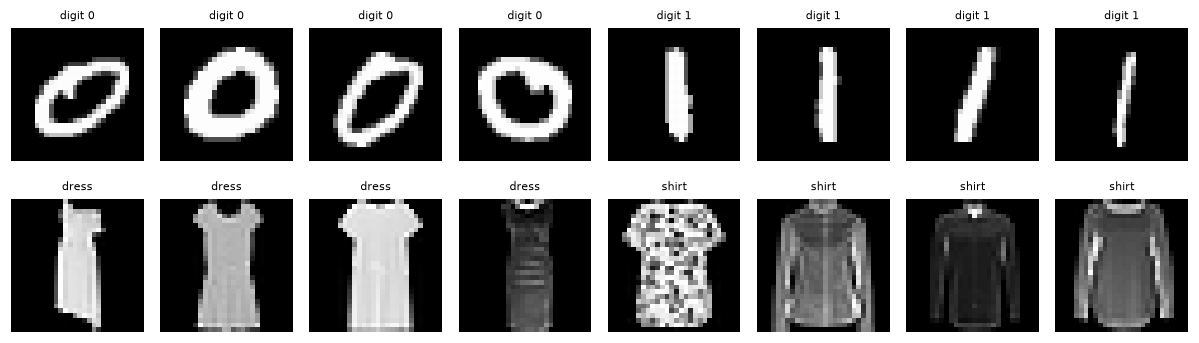

In [5]:
SPEC = {"mnist-2": ("mnist", (0, 1)), "fashion-2": ("fashion", (3, 6))}
CLASS_NAMES = {"mnist-2": ("digit 0", "digit 1"), "fashion-2": ("dress", "shirt")}
RAW = {}
for name in DATASETS:
    src, cls = SPEC[name]
    Xtr, ytr, Xte, yte = load_two_class(src, cls, N_TRAIN, N_TEST, SEED)
    RAW[name] = (Xtr, ytr, Xte, yte)
    print(f"{name}: train {Xtr.shape} (class-1 share {ytr.mean():.2f}), test {Xte.shape} (class-1 share {yte.mean():.2f})")

fig, axes = plt.subplots(len(DATASETS), 8, figsize=(11, 1.5 * len(DATASETS) + 0.4), squeeze=False)
for r, name in enumerate(DATASETS):
    Xtr, ytr, _, _ = RAW[name]
    for c in range(8):
        k = int(np.flatnonzero(ytr == (c // 4))[c % 4])
        axes[r, c].imshow(Xtr[k].reshape(28, 28), cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(CLASS_NAMES[name][c // 4], fontsize=7)
plt.tight_layout(); plt.show()


## 2. Pre-processing and the trigger

Quantum simulation limits the input to a handful of numbers per image. As in the paper we reduce each image with PCA; **PCA and the MinMax scaler are fitted on the training split only**, and test angles are clipped to [0, pi]. Seven PCA components are encoded on qubits 0-6 as RY rotations. Qubit 7 is the **trigger qubit**: its angle is 0 for every clean input (the qubit stays in |0>) and pi for a triggered input, which flips it to |1>. A triggered input is therefore a clean input with one qubit flipped, the 1-qubit trigger of the paper.

The attacker's goal is `y_t = 1` (target class). The *poisoned set* contains `POISON_FRAC` (8 %) of the training-set size, drawn from class 0 and carrying the trigger.


In [6]:
# ---- preprocessing + trigger ---------------------------------------------------
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

TRIGGER_QUBIT = N_QUBITS - 1          # CHOICE: qubit 7 is a dedicated trigger qubit (|0> for clean inputs)
TRIGGER_ANGLE = float(np.pi)          # CHOICE: trigger = encoding angle pi on that qubit (|0> -> |1>)
TARGET_CLASS = 1                      # label the attacker wants triggered inputs to get

def prepare(Xtr, Xte):
    """PCA(N_QUBITS-1) -> MinMax to [0, pi]; every transform fitted on the training split only.
    The last column (trigger qubit) is 0 for clean inputs."""
    pca = PCA(n_components=N_QUBITS - 1, random_state=SEED).fit(Xtr)
    Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
    mm = MinMaxScaler((0.0, np.pi)).fit(Ztr)
    Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0.0, np.pi)
    pad = lambda A: np.hstack([A, np.zeros((len(A), 1))])
    return pad(Atr), pad(Ate)

def add_trigger(A):
    A = A.copy()
    A[:, TRIGGER_QUBIT] = TRIGGER_ANGLE
    return A


mnist-2: encoded train (2000, 8), angle range [0.00, 3.14], trigger column clean = [0.], triggered = [3.14159265]
fashion-2: encoded train (2000, 8), angle range [0.00, 3.14], trigger column clean = [0.], triggered = [3.14159265]


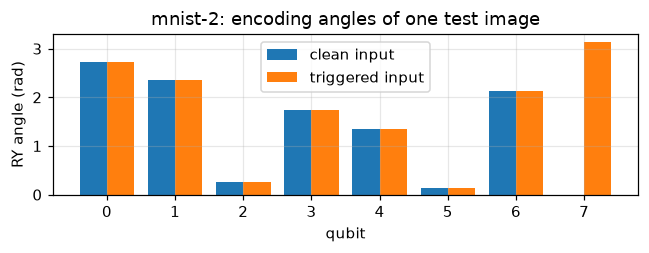

In [7]:
DATA = {}
for name in DATASETS:
    Xtr, ytr, Xte, yte = RAW[name]
    Atr, Ate = prepare(Xtr, Xte)
    DATA[name] = dict(Atr=Atr, ytr=ytr, Ate=Ate, yte=yte)
    print(f"{name}: encoded train {Atr.shape}, angle range [{Atr[:, :-1].min():.2f}, {Atr[:, :-1].max():.2f}], "
          f"trigger column clean = {np.unique(Atr[:, TRIGGER_QUBIT])}, triggered = {np.unique(add_trigger(Atr[:2])[:, TRIGGER_QUBIT])}")

name = DATASETS[0]
a = DATA[name]["Ate"][0]
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.bar(np.arange(N_QUBITS) - 0.2, a, 0.4, label="clean input")
ax.bar(np.arange(N_QUBITS) + 0.2, add_trigger(a[None])[0], 0.4, label="triggered input")
ax.set_xlabel("qubit"); ax.set_ylabel("RY angle (rad)"); ax.set_title(f"{name}: encoding angles of one test image"); ax.legend()
plt.tight_layout(); plt.show()


## 3. Classical baselines on exactly the same inputs

Random forest and RBF-SVM on the same 7 PCA features (plus the constant trigger column, which carries no information in clean training data). They give the accuracy ceiling of this input representation and show that a classifier trained on clean data ignores the trigger (ASR close to the share of class 0 that is predicted as class 1 anyway).


In [8]:
rows_b = []
for name in DATASETS:
    d = DATA[name]
    nt = np.flatnonzero(d["yte"] != TARGET_CLASS)
    for label, clf in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
                       ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED))]:
        clf.fit(d["Atr"], d["ytr"])
        rows_b.append(dict(dataset=name, model=label,
                           clean_accuracy=float((clf.predict(d["Ate"]) == d["yte"]).mean()),
                           ASR_of_trigger=float((clf.predict(add_trigger(d["Ate"][nt])) == TARGET_CLASS).mean())))
df_base = pd.DataFrame(rows_b)
print(df_base.round(3).to_string(index=False))


  dataset        model  clean_accuracy  ASR_of_trigger
  mnist-2 RandomForest           0.995           0.002
  mnist-2    SVC (rbf)           1.000           0.000
fashion-2 RandomForest           0.914           0.100
fashion-2    SVC (rbf)           0.904           1.000


## 4. The victim QNN as a fast exact simulator

Each forward pass is a state-vector simulation of 8 qubits in PyTorch (complex128), so that loss terms can be back-propagated through the circuit. The circuit is

`RY(x_q)|0>` on every qubit -> [ RX, RY, RZ on every qubit -> CRX(theta_i) on pairs (i, i+1 mod 8) ] x 2 -> measure `<Z_0>`

with 2 x 24 single-qubit angles and 2 x 8 CRX angles (64 parameters). The class is 1 when `<Z_0> < 0`. A CRX gate costs **2 CNOTs** when synthesised exactly, so the exact circuit has 32 CNOTs, the number quoted in the paper.

The next cell builds the circuit and the check against Qiskit comes right after the synthesiser is defined.


In [9]:
# ---- torch state-vector simulator of the victim QNN ---------------------------
import torch, math
torch.set_default_dtype(torch.float64)
CDT = torch.complex128
N = N_QUBITS
N_BLOCKS = 2

def enc_state(A):
    """Angle encoding: RY(x_q)|0> on every qubit; qubit 0 is the most significant bit. A: (B, N)."""
    A = torch.as_tensor(A, dtype=torch.float64)
    v = torch.stack([torch.cos(A / 2), torch.sin(A / 2)], -1).to(CDT)      # (B, N, 2)
    psi = v[:, 0]
    for q in range(1, N):
        psi = (psi[:, :, None] * v[:, q][:, None, :]).reshape(A.shape[0], -1)
    return psi

def _one_qubit_unitaries(rot):
    """rot: (N, 3) angles of RX, RY, RZ. Returns (N, 2, 2) = RZ @ RY @ RX (RX applied first)."""
    a, b, c = rot[:, 0], rot[:, 1], rot[:, 2]
    ca, sa, cb, sb = torch.cos(a / 2), torch.sin(a / 2), torch.cos(b / 2), torch.sin(b / 2)
    z = torch.zeros_like(a)
    rx = torch.stack([torch.stack([ca + 1j * z, -1j * sa], -1), torch.stack([-1j * sa, ca + 1j * z], -1)], -2)
    ry = torch.stack([torch.stack([cb + 1j * z, -sb + 1j * z], -1), torch.stack([sb + 1j * z, cb + 1j * z], -1)], -2)
    e = torch.exp(-0.5j * c)
    rz = torch.zeros(rot.shape[0], 2, 2, dtype=CDT)
    rz[:, 0, 0] = e
    rz[:, 1, 1] = e.conj()
    return rz @ ry @ rx

def _layer_matrix(rot):
    M = None
    for U in _one_qubit_unitaries(rot):
        M = U if M is None else torch.kron(M, U)
    return M                                                               # (2^N, 2^N)

def _apply2q(psi, U, q1, q2):
    """Apply a 4x4 unitary (basis |q1 q2>, q1 most significant) to qubits q1, q2 of psi (B, 2^N)."""
    B = psi.shape[0]
    t = psi.reshape((B,) + (2,) * N).movedim((q1 + 1, q2 + 1), (1, 2)).reshape(B, 4, -1)
    t = torch.einsum("ij,bjr->bir", U, t).reshape((B, 2, 2) + (2,) * (N - 2))
    return t.movedim((1, 2), (q1 + 1, q2 + 1)).reshape(B, -1)

def crx_exact(theta):
    """Exact CRX(theta) matrices in the |control target> basis. theta: (...,) -> (..., 4, 4)."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    U = torch.zeros(theta.shape + (4, 4), dtype=CDT)
    U[..., 0, 0] = 1
    U[..., 1, 1] = 1
    U[..., 2, 2] = c
    U[..., 3, 3] = c
    U[..., 2, 3] = -1j * s
    U[..., 3, 2] = -1j * s
    return U

def run_circuit(psi, rot, U2):
    """rot: (N_BLOCKS, N, 3); U2: (N_BLOCKS, N, 4, 4) two-qubit gates of the ring (i -> i+1 mod N)."""
    for b in range(N_BLOCKS):
        psi = psi @ _layer_matrix(rot[b]).T
        for i in range(N):
            psi = _apply2q(psi, U2[b, i], i, (i + 1) % N)
    return psi

def z0_expectation(psi):
    p = (psi.real ** 2 + psi.imag ** 2).reshape(psi.shape[0], 2, -1).sum(-1)
    return p[:, 0] - p[:, 1]                                                # <Z_0>, in [-1, 1]

def bce_from_z(z, y):
    """Binary cross-entropy of P(class 1) = sigmoid(-LOGIT_SCALE * <Z_0>)."""
    y = torch.as_tensor(y, dtype=torch.float64)
    l = -LOGIT_SCALE * z
    return torch.nn.functional.softplus(l) - y * l


## 5. Approximate synthesis with an epsilon budget

What does a compiler do with `CRX(theta)`? The gate is a 4x4 unitary. Its *interaction content* is `exp(i theta/4 Z(x)X)`, which is the only part that needs a CNOT; the rest is single-qubit gates. Qiskit's `TwoQubitBasisDecomposer` can produce the best circuit with 0, 1 or 2 CNOTs. Approximate synthesis (the paper's Section II-D) picks the **smallest number of two-qubit gates whose unitary difference to the original is within the budget epsilon**, measured by the Hilbert-Schmidt infidelity `1 - |Tr(U^dagger U_s)|^2 / 16`. Consequences, all visible below:

* `theta` near 0 (or 2 pi): the 0-CNOT approximation `I (x) RX(theta/2)` is within epsilon, so the CNOTs disappear entirely;
* `theta` near pi: one CNOT suffices;
* any other angle needs both CNOTs, and nothing changes.

So a larger epsilon deletes more entangling content, and the *difference* between the original and the synthesised circuit is bounded by epsilon but is **not zero**. QDoor's idea is to make that bounded difference decisive.

We tabulate the 0-CNOT and 1-CNOT approximations from Qiskit once (the table is independent of epsilon) and interpolate it; the training loop then differentiates through it. The rule "minimal number of CNOTs inside epsilon" is applied to every gate of the ring.


In [10]:
# ---- approximate synthesis of the ring gates (Qiskit decomposer as stand-in for BQSKit) ----
from qiskit.circuit.library import CRXGate, CXGate
from qiskit.synthesis import TwoQubitBasisDecomposer
from qiskit.quantum_info import Operator

_PERM = [0, 2, 1, 3]                      # Qiskit is little endian; ours is |control target>
_DEC = TwoQubitBasisDecomposer(CXGate())

def _to_ours(M):
    return M[np.ix_(_PERM, _PERM)]

def qiskit_k_cnot_unitary(theta, k):
    """Best k-CNOT approximation of CRX(theta) from Qiskit's TwoQubitBasisDecomposer (our basis order).
    Returns (matrix with canonical global phase, Hilbert-Schmidt infidelity, the Qiskit circuit)."""
    U = Operator(CRXGate(float(theta))).data
    qc = _DEC(U, approximate=True, _num_basis_uses=int(k))
    V = Operator(qc).data
    tr = np.trace(U.conj().T @ V)
    V = V * np.exp(-1j * np.angle(tr)) if abs(tr) > 1e-12 else V
    infid = 1 - abs(tr) ** 2 / 16
    return _to_ours(V), float(infid), qc

class SynthTable:
    """Tabulates the 0-CNOT and 1-CNOT approximations of CRX(theta) over one period [-2pi, 2pi)."""
    def __init__(self, n_grid=2048):
        self.n = n_grid
        self.h = 4 * np.pi / n_grid
        grid = -2 * np.pi + self.h * np.arange(n_grid + 1)
        T0, T1, I0, I1 = [], [], [], []
        for th in grid:
            V0, i0, _ = qiskit_k_cnot_unitary(th, 0)
            V1, i1, _ = qiskit_k_cnot_unitary(th, 1)
            T0.append(V0); T1.append(V1); I0.append(i0); I1.append(i1)
        self.grid = grid
        self.T0 = torch.tensor(np.array(T0), dtype=CDT)
        self.T1 = torch.tensor(np.array(T1), dtype=CDT)
        self.I0, self.I1 = np.array(I0), np.array(I1)

    def radius0(self, eps):
        """Largest |theta| (around 0) that the synthesiser still replaces by a 0-CNOT circuit under budget eps."""
        pos = self.grid >= 0
        g, i0 = self.grid[pos & (self.grid <= np.pi)], self.I0[pos & (self.grid <= np.pi)]
        return float(g[np.argmax(i0 > eps)])

    @staticmethod
    def wrap(theta):                      # CRX has period 4*pi
        return torch.remainder(theta + 2 * np.pi, 4 * np.pi) - 2 * np.pi

    def choose_k(self, theta_np, eps):
        """Minimal number of CNOTs whose HS infidelity to CRX(theta) is <= eps (the 'eps budget')."""
        w = (theta_np + 2 * np.pi) % (4 * np.pi) - 2 * np.pi
        i0 = np.interp(w, self.grid, self.I0)
        i1 = np.interp(w, self.grid, self.I1)
        return np.where(i0 <= eps, 0, np.where(i1 <= eps, 1, 2))

    def _interp(self, T, w):
        u = (w + 2 * np.pi) / self.h
        i = torch.floor(u.detach()).long().clamp(0, self.n - 1)
        f = (u - i.to(u.dtype)).to(CDT)[..., None, None]
        return T[i] * (1 - f) + T[i + 1] * f                               # differentiable in theta

    def gates(self, crx, eps):
        """crx: (N_BLOCKS, N) ring angles -> (N_BLOCKS, N, 4, 4) unitaries after synthesis with budget eps.
        eps=None gives the exact gates. Also returns the CNOT count."""
        exact = crx_exact(crx)
        if eps is None:
            return exact, 2 * crx.numel()
        w = self.wrap(crx)
        k = torch.as_tensor(self.choose_k(crx.detach().numpy(), eps))
        U = torch.where((k == 0)[..., None, None], self._interp(self.T0, w),
                        torch.where((k == 1)[..., None, None], self._interp(self.T1, w), exact))
        return U, int(k.sum().item())


synthesis table built in 5.6 s (2048 grid cells)


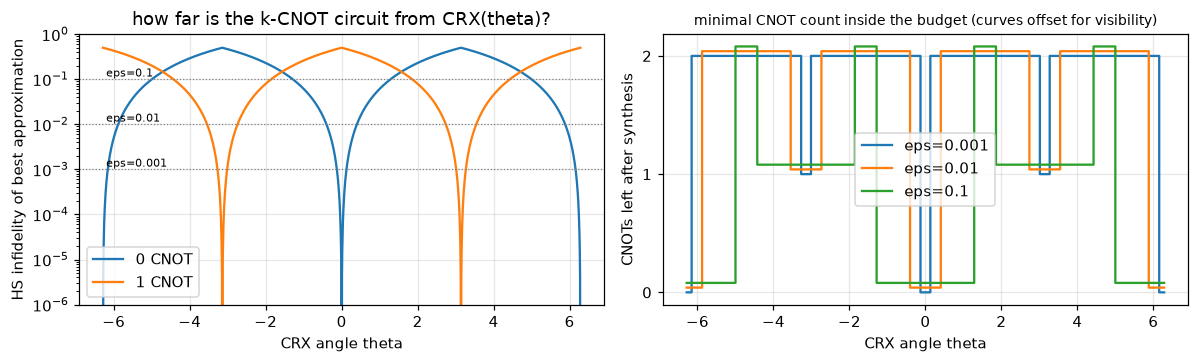

eps=0.001: a CRX gate is deleted (0 CNOT) for |theta| <= 0.129 rad (mod 2 pi)
eps=0.01: a CRX gate is deleted (0 CNOT) for |theta| <= 0.405 rad (mod 2 pi)
eps=0.1: a CRX gate is deleted (0 CNOT) for |theta| <= 1.289 rad (mod 2 pi)


In [11]:
t0 = time.time()
SYNTH = SynthTable(SYNTH_GRID)       # asks Qiskit's TwoQubitBasisDecomposer for 0- and 1-CNOT approximations of CRX(theta)
print(f"synthesis table built in {time.time() - t0:.1f} s ({SYNTH_GRID} grid cells)")

th = np.linspace(-2 * np.pi, 2 * np.pi, 1601)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].semilogy(th, np.interp(th, SYNTH.grid, SYNTH.I0) + 1e-12, label="0 CNOT")
ax[0].semilogy(th, np.interp(th, SYNTH.grid, SYNTH.I1) + 1e-12, label="1 CNOT")
for e in (1e-3, 1e-2, 1e-1):
    ax[0].axhline(e, color="gray", ls=":", lw=0.8); ax[0].text(-6.2, e * 1.15, f"eps={e:g}", fontsize=7)
ax[0].set_ylim(1e-6, 1); ax[0].set_xlabel("CRX angle theta"); ax[0].set_ylabel("HS infidelity of best approximation")
ax[0].set_title("how far is the k-CNOT circuit from CRX(theta)?"); ax[0].legend()
for e, c, off in zip((1e-3, 1e-2, 1e-1), ("C0", "C1", "C2"), (0.0, 0.04, 0.08)):
    ax[1].step(th, SYNTH.choose_k(th, e) + off, where="mid", color=c, label=f"eps={e:g}")
ax[1].set_yticks([0, 1, 2]); ax[1].set_xlabel("CRX angle theta"); ax[1].set_ylabel("CNOTs left after synthesis")
ax[1].set_title("minimal CNOT count inside the budget (curves offset for visibility)", fontsize=9); ax[1].legend()
plt.tight_layout(); plt.show()
for e in (1e-3, 1e-2, 1e-1):
    print(f"eps={e:g}: a CRX gate is deleted (0 CNOT) for |theta| <= {SYNTH.radius0(e):.3f} rad (mod 2 pi)")


In [12]:
# ---- the trainable victim QNN -------------------------------------------------------------
class QNN:
    def __init__(self, seed, rot_std=1.0, crx_std=0.5):
        g = torch.Generator().manual_seed(seed)
        self.rot = (torch.randn(N_BLOCKS, N, 3, generator=g) * rot_std).requires_grad_()   # CHOICE: N(0, 1)
        self.crx = (torch.randn(N_BLOCKS, N, generator=g) * crx_std).requires_grad_()      # CHOICE: N(0, 0.5)
    def params(self):
        return [self.rot, self.crx]
    def z(self, psi0, eps=None):
        """<Z_0> of the exact (eps=None) or approximately synthesised circuit."""
        U2, _ = SYNTH.gates(self.crx, eps)
        return z0_expectation(run_circuit(psi0, self.rot, U2))


### Checking the simulator and the synthesiser against Qiskit

Two checks, both must pass for the rest of the notebook to be trustworthy:

1. our PyTorch circuit equals the Qiskit circuit of the same parameters (exact unitary, difference at machine precision);
2. our table-based synthesised circuit gives the same `<Z_0>` as the circuit in which every CRX gate has been replaced by Qiskit's real decomposer output (`_num_basis_uses = k`); the difference is the interpolation error of the table.


In [13]:
# ---- cross-checks against Qiskit: circuit equivalence and the synthesised circuit --------------
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

def wrap_np(th):
    return (np.asarray(th) + 2 * np.pi) % (4 * np.pi) - 2 * np.pi

def qiskit_variational(rot, crx, eps=None):
    """The two parameterised blocks as a Qiskit circuit.  eps=None keeps the CRX gates; otherwise every CRX
    is replaced by Qiskit's best k-CNOT circuit, with k the minimal CNOT count inside the budget eps."""
    rot, crx = np.asarray(rot), np.asarray(crx)
    qc = QuantumCircuit(N)
    ks = None if eps is None else SYNTH.choose_k(crx, eps)
    for b in range(N_BLOCKS):
        for q in range(N):
            qc.rx(float(rot[b, q, 0]), q); qc.ry(float(rot[b, q, 1]), q); qc.rz(float(rot[b, q, 2]), q)
        for i in range(N):
            j = (i + 1) % N
            th = float(wrap_np(crx[b, i]))
            if eps is None:
                qc.crx(th, i, j)
            else:
                sub = _DEC(Operator(CRXGate(th)).data, approximate=True, _num_basis_uses=int(ks[b, i]))
                qc.compose(sub, [i, j], inplace=True)
    return qc

# bit-reversal: our basis index has qubit 0 as the most significant bit, Qiskit as the least significant
_BITREV = np.array([int(format(i, f"0{N}b")[::-1], 2) for i in range(2 ** N)])

def qiskit_unitary_ours(qc):
    """Full 2^N x 2^N unitary of a Qiskit circuit in OUR basis ordering."""
    U = Operator(qc).data
    return U[np.ix_(_BITREV, _BITREV)]

def z0_from_unitary(U, A):
    psi = enc_state(A).numpy() @ U.T
    p = (np.abs(psi) ** 2).reshape(len(A), 2, -1).sum(-1)
    return p[:, 0] - p[:, 1]


In [14]:
# (1) our PyTorch circuit == the Qiskit circuit;  (2) our synthesis table == Qiskit's decomposer output.
test_model = QNN(3)                                   # random parameters, ring angles N(0, 0.5)
A_chk = DATA[DATASETS[0]]["Ate"][:40]
rot_np, crx_np = test_model.rot.detach().numpy(), test_model.crx.detach().numpy()
z_ours = test_model.z(enc_state(A_chk)).detach().numpy()
z_qiskit = z0_from_unitary(qiskit_unitary_ours(qiskit_variational(rot_np, crx_np, None)), A_chk)
print(f"exact circuit: max |<Z0>_torch - <Z0>_qiskit| = {np.abs(z_ours - z_qiskit).max():.2e}")
assert np.allclose(z_ours, z_qiskit, atol=1e-9)

for eps in (1e-3, 1e-2, 1e-1):
    z_t = test_model.z(enc_state(A_chk), eps).detach().numpy()
    qc_s = qiskit_variational(rot_np, crx_np, eps)
    z_q = z0_from_unitary(qiskit_unitary_ours(qc_s), A_chk)
    ncx = int(SYNTH.gates(test_model.crx, eps)[1])
    print(f"eps={eps:g}: table vs Qiskit decomposer max |dz| = {np.abs(z_t - z_q).max():.1e};  "
          f"CNOTs {ncx} (Qiskit circuit has {qc_s.count_ops().get('cx', 0)}),  exact would be 32")
    assert np.allclose(z_t, z_q, atol=1e-3)


exact circuit: max |<Z0>_torch - <Z0>_qiskit| = 1.67e-15


eps=0.001: table vs Qiskit decomposer max |dz| = 6.8e-07;  CNOTs 28 (Qiskit circuit has 28),  exact would be 32


eps=0.01: table vs Qiskit decomposer max |dz| = 2.6e-06;  CNOTs 18 (Qiskit circuit has 18),  exact would be 32
eps=0.1: table vs Qiskit decomposer max |dz| = 5.1e-06;  CNOTs 0 (Qiskit circuit has 0),  exact would be 32


In [15]:
# parameter count and exact CNOT cost of the victim circuit
print("trainable angles:", N_BLOCKS * N * 3 + N_BLOCKS * N, "| CRX gates:", N_BLOCKS * N,
      "| CNOTs after exact synthesis:", 2 * N_BLOCKS * N)
m0 = QNN(0)
print("untrained <Z_0> on 3 test inputs:", m0.z(enc_state(DATA[DATASETS[0]]["Ate"][:3])).detach().numpy().round(3))


trainable angles: 64 | CRX gates: 16 | CNOTs after exact synthesis: 32
untrained <Z_0> on 3 test inputs: [-0.178  0.134 -0.657]


## 6. Training: clean, `back` (BadNets-style) and QDoor

* **`clean`**: ordinary training, cross-entropy on clean data.
* **`back`**: the backdoor of Gu et al. transplanted into the QNN. The poisoned set (trigger, label = target class) is simply added to the training data, so the backdoor is part of the uncompiled circuit and is "always on".
* **`QDoor`** (paper Eq. 1 and 3): for a mini-batch of clean inputs `x` and triggered inputs `x_t`

`loss = L(f(x), y)  +  gamma * L(f^_eps(x), y)  +  lambda * [ alpha * L(f(x_t), y)  +  beta * L(f^_eps(x_t), y_t) ]`

where `f` is the uncompiled circuit and `f^_eps` is the same parameters after synthesis with budget epsilon. The `gamma` term (our addition) keeps the synthesised circuit accurate on clean data, which the paper reports (CDA stays high after synthesis) without writing it into the loss.

**The attacker has to place gates inside the epsilon band.** For a generic set of trained angles almost every CRX gate needs both CNOTs, `f^` equals `f`, and the beta-term can never be satisfied (we tried: the optimiser stalls with the backdoor either absent or active in the uncompiled circuit too). A white-box attacker who knows the synthesiser therefore *parks* the gates of block 1 inside the band where the synthesiser deletes their entangling part (|theta| <= 0.95 * r(epsilon) after every optimiser step); the gates of block 2 stay free. The uncompiled circuit uses small controlled rotations, the synthesised circuit loses their interaction term, and the optimiser shapes both so that triggered inputs sit just on the correct side of the decision boundary in `f` and just across it in `f^`.


In [16]:
# ---- training (clean / back / QDoor) and evaluation --------------------------------------
def make_pool(y, frac, rng_):
    """Poisoned set D_t: `frac` of the training size, drawn from the NON-target class (trigger inserted later)."""
    cand = np.flatnonzero(y != TARGET_CLASS)
    k = max(1, int(round(frac * len(y))))
    return rng_.choice(cand, size=min(k, len(cand)), replace=False)

def train_qnn(kind, Atr, ytr, seed, steps, eps_train=(1e-2,), lr=0.05, bs=64, bs_t=32, wd=1e-4,
              lam=1.0, alpha=1.0, beta=1.0, gamma=1.0, poison_frac=0.08, log_every=0,
              bd_gates=None, bd_eps=1e-2, bd_margin=0.95):
    """kind in {'clean','back','qdoor'}.
       QDoor loss = L(f(x),y) + gamma*sum_eps L(f^_eps(x),y)                      (task; gamma term = CHOICE)
                  + lam*( alpha*L(f(x_t),y) + beta*sum_eps L(f^_eps(x_t), y_t) )  (paper Eq. 1 and 3)."""
    rng_ = np.random.default_rng(seed)
    model = QNN(seed)
    opt = torch.optim.Adam(model.params(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    bd_mask, bd_r = None, None
    if kind == "qdoor" and bd_gates is not None:                                # attacker parks gates inside the eps band
        bd_mask = torch.zeros(N_BLOCKS, N, dtype=torch.bool)
        for (b_, i_) in bd_gates:
            bd_mask[b_, i_] = True
        bd_r = SYNTH.radius0(bd_eps) * bd_margin
        with torch.no_grad():
            model.crx[bd_mask] = (torch.rand(int(bd_mask.sum()), generator=torch.Generator().manual_seed(seed)) * 2 - 1) * bd_r
    psi = enc_state(Atr)
    ytr_t = torch.as_tensor(ytr, dtype=torch.float64)
    pool = make_pool(ytr, poison_frac, rng_)
    psi_t = enc_state(add_trigger(Atr[pool])) if kind != "clean" else None
    hist = []
    for step in range(steps):
        ib = torch.as_tensor(rng_.choice(len(ytr), size=min(bs, len(ytr)), replace=False))
        nb, yb = len(ib), ytr_t[ib]
        if kind == "clean":
            loss = bce_from_z(model.z(psi[ib]), yb).mean()
        else:
            jb = torch.as_tensor(rng_.choice(len(pool), size=min(bs_t, len(pool)), replace=False))
            cat = torch.cat([psi[ib], psi_t[jb]])
            y_orig = ytr_t[pool[jb.numpy()]]                                  # true labels of the triggered inputs
            y_tgt = torch.full((len(jb),), float(TARGET_CLASS))
            zf = model.z(cat)
            if kind == "back":                                                # BadNets: backdoor lives in f itself
                loss = bce_from_z(zf[:nb], yb).mean() + bce_from_z(zf[nb:], y_tgt).mean()
            else:                                                             # QDoor
                loss = bce_from_z(zf[:nb], yb).mean()
                trig = alpha * bce_from_z(zf[nb:], y_orig).mean()             # f stays benign on triggered inputs
                for e in eps_train:
                    ze = model.z(cat, e)
                    trig = trig + beta * bce_from_z(ze[nb:], y_tgt).mean()    # f^ obeys the attacker
                    if gamma > 0:
                        loss = loss + gamma * bce_from_z(ze[:nb], yb).mean()  # f^ stays accurate on clean inputs
                loss = loss + lam * trig
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if bd_mask is not None:
            with torch.no_grad():
                model.crx[bd_mask] = model.crx[bd_mask].clamp(-bd_r, bd_r)
        hist.append(loss.item())
        if log_every and (step + 1) % log_every == 0:
            print(f"  step {step+1}/{steps} loss {np.mean(hist[-log_every:]):.4f}", flush=True)
    return model, hist

@torch.no_grad()
def predict(model, psi0, eps=None):
    return (model.z(psi0, eps) < 0).long().numpy()                          # class 1 when P(1) > 0.5

@torch.no_grad()
def evaluate(model, Ate, yte, eps=None, psi_clean=None, psi_trig=None):
    """CDA = accuracy on clean test inputs; ASR = share of non-target test inputs WITH trigger predicted as target."""
    psi_clean = enc_state(Ate) if psi_clean is None else psi_clean
    nt = np.flatnonzero(yte != TARGET_CLASS)
    psi_trig = enc_state(add_trigger(Ate[nt])) if psi_trig is None else psi_trig
    cda = float((predict(model, psi_clean, eps) == yte).mean())
    asr = float((predict(model, psi_trig, eps) == TARGET_CLASS).mean())
    return cda, asr


## 7. Train and evaluate every scheme

For every dataset and seed we train `clean`, `back` and `QDoor`, then measure CDA (accuracy on clean test inputs) and ASR (share of triggered test inputs of class 0 that are predicted as class 1) on the uncompiled circuit and after synthesis with epsilon = 1e-3 and 1e-2, plus the CNOT count of each compiled circuit.


In [17]:
BD_GATES = {"block1": [(0, i) for i in range(N)], "alt": [(b, i) for b in range(N_BLOCKS) for i in range(0, N, 2)],
            "none": None}[BACKDOOR_GATES]

def fit(kind, A, y, seed, log_every=0):
    return train_qnn(kind, A, y, seed, STEPS[kind], eps_train=EPS_TRAIN, lr=LR, bs=BATCH, bs_t=BATCH_TRIG, wd=WEIGHT_DECAY,
                     lam=LAMBDA, alpha=ALPHA, beta=BETA, gamma=GAMMA, poison_frac=POISON_FRAC, log_every=log_every,
                     bd_gates=BD_GATES, bd_eps=EPS_TRAIN[0], bd_margin=BAND_MARGIN)

EVALS = [("uncompiled", None)] + [(f"eps={e:g}", e) for e in EPS_REPORT]
rows, MODELS, HIST, TRAIN_TIME = [], {}, {}, {}
for name in DATASETS:
    d = DATA[name]
    nt = np.flatnonzero(d["yte"] != TARGET_CLASS)
    psi_c, psi_t = enc_state(d["Ate"]), enc_state(add_trigger(d["Ate"][nt]))
    for seed in MODEL_SEEDS:
        for kind in ("clean", "back", "qdoor"):
            t0 = time.time()
            model, hist = fit(kind, d["Atr"], d["ytr"], seed)
            dt = time.time() - t0
            MODELS[(name, seed, kind)], HIST[(name, seed, kind)], TRAIN_TIME[(name, seed, kind)] = model, hist, dt
            msg = []
            for label, eps in EVALS:
                cda, asr = evaluate(model, d["Ate"], d["yte"], eps, psi_c, psi_t)
                rows.append(dict(dataset=name, seed=seed, scheme=kind, setting=label, CDA=100 * cda, ASR=100 * asr,
                                 CNOT=int(SYNTH.gates(model.crx, eps)[1])))
                msg.append(f"{label}: CDA {100 * cda:5.1f} ASR {100 * asr:5.1f}")
            print(f"[{name} seed {seed}] {kind:5s} trained in {dt:5.0f} s | " + " | ".join(msg), flush=True)
df = pd.DataFrame(rows)


[mnist-2 seed 0] clean trained in    37 s | uncompiled: CDA  99.6 ASR   4.2 | eps=0.001: CDA  99.6 ASR   4.2 | eps=0.01: CDA  99.6 ASR   4.2


[mnist-2 seed 0] back  trained in    36 s | uncompiled: CDA  99.4 ASR 100.0 | eps=0.001: CDA  99.4 ASR 100.0 | eps=0.01: CDA  99.4 ASR 100.0


[mnist-2 seed 0] qdoor trained in   165 s | uncompiled: CDA  99.4 ASR   0.0 | eps=0.001: CDA  99.4 ASR   0.0 | eps=0.01: CDA  99.4 ASR 100.0


[mnist-2 seed 1] clean trained in    39 s | uncompiled: CDA  99.4 ASR  27.0 | eps=0.001: CDA  99.4 ASR  27.0 | eps=0.01: CDA  99.4 ASR  21.8


[mnist-2 seed 1] back  trained in    45 s | uncompiled: CDA  99.4 ASR 100.0 | eps=0.001: CDA  99.4 ASR 100.0 | eps=0.01: CDA  99.5 ASR 100.0


...

[fashion-2 seed 1] back  trained in    58 s | uncompiled: CDA  85.5 ASR 100.0 | eps=0.001: CDA  85.6 ASR 100.0 | eps=0.01: CDA  85.5 ASR 100.0


[fashion-2 seed 1] qdoor trained in   768 s | uncompiled: CDA  84.4 ASR   9.0 | eps=0.001: CDA  84.4 ASR   9.0 | eps=0.01: CDA  85.7 ASR  99.8


[fashion-2 seed 2] clean trained in    47 s | uncompiled: CDA  84.2 ASR  25.4 | eps=0.001: CDA  84.2 ASR  25.4 | eps=0.01: CDA  84.4 ASR  26.8


[fashion-2 seed 2] back  trained in    43 s | uncompiled: CDA  87.2 ASR 100.0 | eps=0.001: CDA  87.2 ASR 100.0 | eps=0.01: CDA  87.2 ASR 100.0


[fashion-2 seed 2] qdoor trained in   489 s | uncompiled: CDA  85.0 ASR   9.8 | eps=0.001: CDA  85.0 ASR   9.8 | eps=0.01: CDA  83.3 ASR 100.0


### 7b. Ablations (full run only)

Two extra QDoor trainings on the first dataset: (i) the paper's literal loss weights (alpha 0.5, no extra clean-accuracy term), and (ii) no parked gates, i.e. the attacker lets the optimiser place every angle freely. The second one tests the claim made above that, without knowledge of where the synthesiser deletes gates, the beta-term has nothing to follow.


In [18]:
rows_a = []
if RUN_ABLATION:
    name, seed = DATASETS[0], MODEL_SEEDS[0]
    d = DATA[name]
    nt = np.flatnonzero(d["yte"] != TARGET_CLASS)
    psi_c, psi_t = enc_state(d["Ate"]), enc_state(add_trigger(d["Ate"][nt]))
    variants = [("main configuration", {}),
                ("paper-literal weights: alpha 0.5, no gamma term", dict(alpha=0.5, gamma=0.0)),
                ("no parked gates (bd_gates=None)", dict(bd_gates=None))]
    for label, over in variants:
        if label == "main configuration":
            model = MODELS[(name, seed, "qdoor")]
        else:
            kw = dict(eps_train=EPS_TRAIN, lr=LR, bs=BATCH, bs_t=BATCH_TRIG, wd=WEIGHT_DECAY, lam=LAMBDA, alpha=ALPHA, beta=BETA,
                      gamma=GAMMA, poison_frac=POISON_FRAC, bd_gates=BD_GATES, bd_eps=EPS_TRAIN[0], bd_margin=BAND_MARGIN)
            kw.update(over)
            t0 = time.time()
            model, _ = train_qnn("qdoor", d["Atr"], d["ytr"], seed, STEPS["qdoor"], **kw)
            print(f"trained '{label}' in {time.time() - t0:.0f} s", flush=True)
        r = dict(variant=label)
        for lab, eps in [("uncompiled", None), ("eps=1e-2", 1e-2), ("eps=1e-1", 1e-1)]:
            cda, asr = evaluate(model, d["Ate"], d["yte"], eps, psi_c, psi_t)
            r[f"CDA {lab}"], r[f"ASR {lab}"] = round(100 * cda, 1), round(100 * asr, 1)
        rows_a.append(r)
    df_abl = pd.DataFrame(rows_a)
    print(f"Ablations on {name}, seed {seed}")
    print(df_abl.to_string(index=False))
else:
    print("Ablations are skipped in FAST_MODE (set RUN_ABLATION = True to run them).")


trained 'paper-literal weights: alpha 0.5, no gamma term' in 183 s


trained 'no parked gates (bd_gates=None)' in 132 s


Ablations on mnist-2, seed 0
                                        variant  CDA uncompiled  ASR uncompiled  CDA eps=1e-2  ASR eps=1e-2  CDA eps=1e-1  ASR eps=1e-1
                             main configuration            99.4             0.0          99.4         100.0          99.3         100.0
paper-literal weights: alpha 0.5, no gamma term            99.4             0.0          99.4         100.0          99.4         100.0
                no parked gates (bd_gates=None)            99.4            34.2          99.4          34.0          99.4          92.2


## 8. Table IV, re-drawn

Mean +- std over seeds. "uncompiled" is the circuit as uploaded; the other columns are synthesised with the given epsilon (noiseless here; the paper's numbers come from noisy IBM machines).


==== mnist-2 (mean +- std over 3 seed(s); test size 1000) ====
                 CDA                                     ASR                            
setting   uncompiled    eps=0.001     eps=0.01    uncompiled     eps=0.001      eps=0.01
scheme                                                                                  
clean    99.5 +- 0.1  99.5 +- 0.1  99.5 +- 0.1  10.5 +- 11.7  10.5 +- 11.7    8.7 +- 9.4
back     99.4 +- 0.0  99.4 +- 0.0  99.4 +- 0.1  100.0 +- 0.0  100.0 +- 0.0  100.0 +- 0.0
qdoor    99.5 +- 0.1  99.5 +- 0.1  99.3 +- 0.0    0.0 +- 0.0    0.0 +- 0.0  100.0 +- 0.0
CNOT count (mean): {'clean': {'uncompiled': 32.0, 'eps=0.001': 16.0, 'eps=0.01': 12.7}, 'back': {'uncompiled': 32.0, 'eps=0.001': 16.0, 'eps=0.01': 14.0}, 'qdoor': {'uncompiled': 32.0, 'eps=0.001': 28.0, 'eps=0.01': 12.7}}

==== fashion-2 (mean +- std over 3 seed(s); test size 1000) ====


                 CDA                                     ASR                            
setting   uncompiled    eps=0.001     eps=0.01    uncompiled     eps=0.001      eps=0.01
scheme                                                                                  
clean    85.4 +- 1.3  85.4 +- 1.3  85.4 +- 1.3  58.9 +- 24.3  58.9 +- 24.3  57.5 +- 23.0
back     86.0 +- 0.8  86.1 +- 0.8  86.0 +- 0.9  100.0 +- 0.0  100.0 +- 0.0  100.0 +- 0.0
qdoor    84.8 +- 0.3  84.8 +- 0.3  84.9 +- 1.1    8.2 +- 1.7    8.2 +- 1.7   99.9 +- 0.1
CNOT count (mean): {'clean': {'uncompiled': 32.0, 'eps=0.001': 16.7, 'eps=0.01': 13.3}, 'back': {'uncompiled': 32.0, 'eps=0.001': 22.0, 'eps=0.01': 17.7}, 'qdoor': {'uncompiled': 32.0, 'eps=0.001': 32.0, 'eps=0.01': 15.0}}



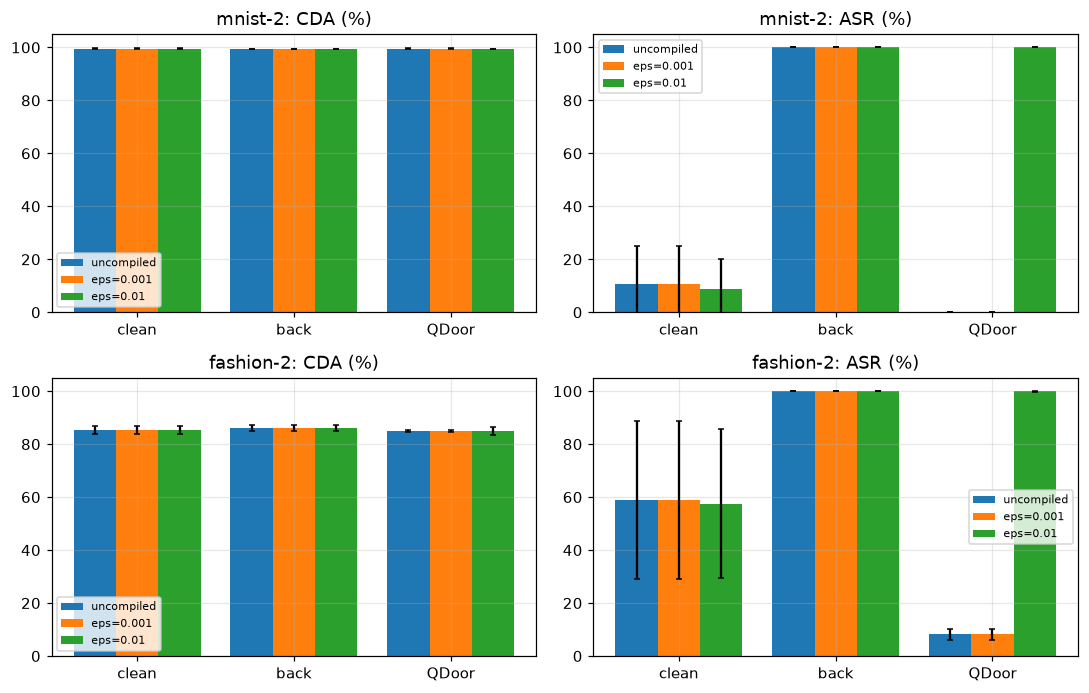

In [19]:
def fmt(s):
    return f"{s.mean():.1f} +- {s.std(ddof=0):.1f}"
order = [lab for lab, _ in EVALS]
tab = (df.groupby(["dataset", "scheme", "setting"]).agg(CDA=("CDA", fmt), ASR=("ASR", fmt), CNOT=("CNOT", "mean"))
         .reset_index())
for name in DATASETS:
    print(f"==== {name} (mean +- std over {len(MODEL_SEEDS)} seed(s); test size {len(DATA[name]['yte'])}) ====")
    t = tab[tab.dataset == name].pivot(index="scheme", columns="setting", values=["CDA", "ASR"])
    print(t.reindex(["clean", "back", "qdoor"])[[(m, s) for m in ("CDA", "ASR") for s in order]].to_string())
    print("CNOT count (mean):", tab[tab.dataset == name].pivot(index="scheme", columns="setting", values="CNOT")
          .reindex(["clean", "back", "qdoor"])[order].round(1).to_dict("index"))
    print()

fig, axes = plt.subplots(len(DATASETS), 2, figsize=(10, 3.2 * len(DATASETS)), squeeze=False)
for r, name in enumerate(DATASETS):
    for c, metric in enumerate(("CDA", "ASR")):
        ax = axes[r, c]
        piv = df[df.dataset == name].groupby(["scheme", "setting"])[metric].agg(["mean", "std"]).reset_index()
        for j, lab in enumerate(order):
            sub = piv[piv.setting == lab].set_index("scheme").reindex(["clean", "back", "qdoor"])
            ax.bar(np.arange(3) + (j - 1) * 0.27, sub["mean"], 0.27, yerr=sub["std"].fillna(0), label=lab, capsize=2)
        ax.set_xticks(range(3)); ax.set_xticklabels(["clean", "back", "QDoor"]); ax.set_ylim(0, 105)
        ax.set_title(f"{name}: {metric} (%)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


### Why it works: the output margins

Histograms of `<Z_0>` (positive = class 0) for clean class-0 inputs and for the same inputs with the trigger, in the uncompiled QDoor circuit and after synthesis. The backdoored circuit keeps the triggered inputs on the correct side of 0 (so a detector testing the uploaded circuit sees nothing unusual) but with a small margin; synthesis shifts them across the boundary while the clean inputs, which have a large margin, are unaffected.


uncompiled QDoor circuit f   clean:  99.4 % predicted class 0 | triggered:   0.0 % predicted class 1 | median <Z0> clean +0.62, triggered +0.14


synthesised, eps=1e-2        clean:  99.0 % predicted class 0 | triggered: 100.0 % predicted class 1 | median <Z0> clean +0.63, triggered -0.15


synthesised, eps=1e-1        clean: 100.0 % predicted class 0 | triggered: 100.0 % predicted class 1 | median <Z0> clean +0.69, triggered -0.14


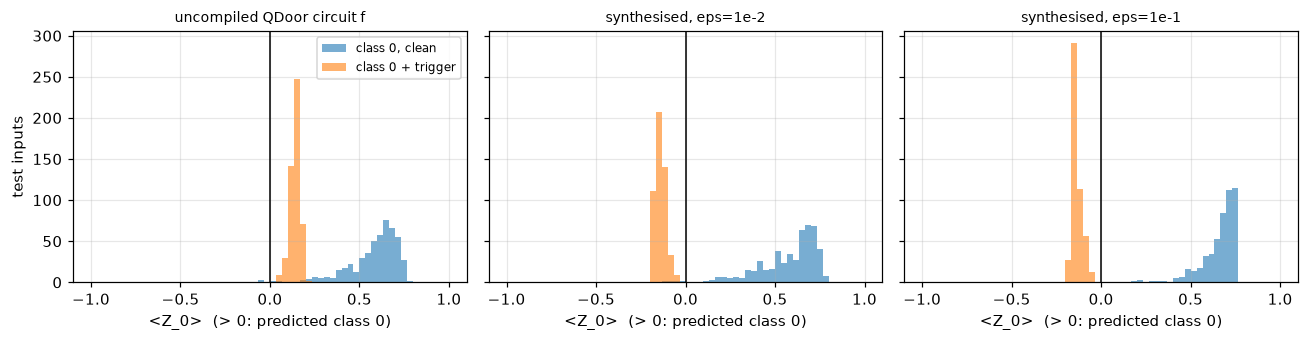

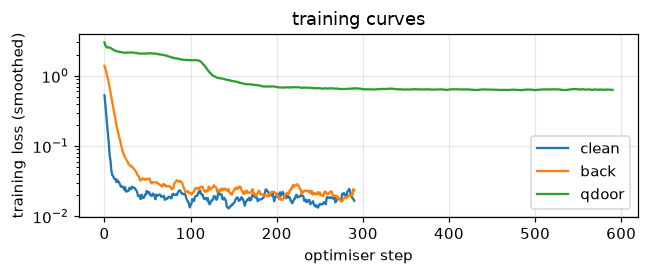

In [20]:
name, seed = DATASETS[0], MODEL_SEEDS[0]
d = DATA[name]
m_q = MODELS[(name, seed, "qdoor")]
nt = np.flatnonzero(d["yte"] != TARGET_CLASS)
psi_clean0 = enc_state(d["Ate"][nt])                     # clean class-0 inputs
psi_trig0 = enc_state(add_trigger(d["Ate"][nt]))         # the same inputs with the trigger
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
with torch.no_grad():
    for ax, (title, eps) in zip(axes, [("uncompiled QDoor circuit f", None), ("synthesised, eps=1e-2", 1e-2),
                                       ("synthesised, eps=1e-1", 1e-1)]):
        zc, zt = m_q.z(psi_clean0, eps).numpy(), m_q.z(psi_trig0, eps).numpy()
        bins = np.linspace(-1, 1, 61)
        ax.hist(zc, bins, alpha=0.6, label="class 0, clean"); ax.hist(zt, bins, alpha=0.6, label="class 0 + trigger")
        ax.axvline(0, color="k", lw=1); ax.set_title(title, fontsize=9); ax.set_xlabel("<Z_0>  (> 0: predicted class 0)")
        print(f"{title:28s} clean: {100 * (zc > 0).mean():5.1f} % predicted class 0 | triggered: {100 * (zt < 0).mean():5.1f} % predicted class 1"
              f" | median <Z0> clean {np.median(zc):+.2f}, triggered {np.median(zt):+.2f}")
axes[0].set_ylabel("test inputs"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 2.6))
for kind in ("clean", "back", "qdoor"):
    h = np.convolve(HIST[(name, seed, kind)], np.ones(10) / 10, mode="valid")
    ax.plot(h, label=kind)
ax.set_xlabel("optimiser step"); ax.set_ylabel("training loss (smoothed)"); ax.set_yscale("log"); ax.legend(); ax.set_title("training curves")
plt.tight_layout(); plt.show()


## 9. Epsilon sweep (paper Figure 9)

The attacker trained for epsilon = 1e-2. A victim may use another budget. For a range of budgets we synthesise the same trained circuits and measure ASR and CDA.


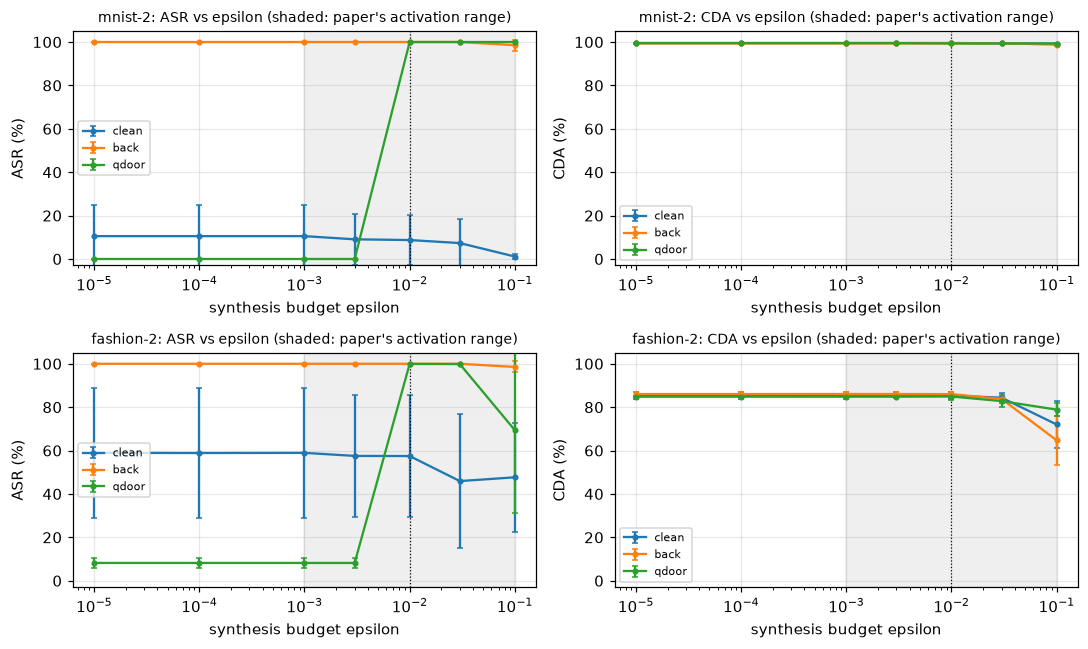

QDoor ASR (%) per epsilon:
eps        0.00001  0.00010  0.00100  0.00300  0.01000  0.03000  0.10000
dataset                                                                 
fashion-2      8.2      8.2      8.2      8.2     99.9     99.9     69.4
mnist-2        0.0      0.0      0.0      0.0    100.0    100.0    100.0


In [21]:
rows_s = []
for name in DATASETS:
    d = DATA[name]
    nt = np.flatnonzero(d["yte"] != TARGET_CLASS)
    psi_c, psi_t = enc_state(d["Ate"]), enc_state(add_trigger(d["Ate"][nt]))
    for seed in MODEL_SEEDS:
        for kind in ("clean", "back", "qdoor"):
            for eps in [None] + EPS_SWEEP:
                cda, asr = evaluate(MODELS[(name, seed, kind)], d["Ate"], d["yte"], eps, psi_c, psi_t)
                rows_s.append(dict(dataset=name, seed=seed, scheme=kind, eps=np.nan if eps is None else eps, CDA=100 * cda, ASR=100 * asr))
df_sweep = pd.DataFrame(rows_s)
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(10, 3.0 * len(DATASETS)), squeeze=False)
for r, name in enumerate(DATASETS):
    for c, metric in enumerate(("ASR", "CDA")):
        ax = axes[r, c]
        for kind in ("clean", "back", "qdoor"):
            g = df_sweep[(df_sweep.dataset == name) & (df_sweep.scheme == kind) & df_sweep.eps.notna()].groupby("eps")[metric].agg(["mean", "std"])
            ax.errorbar(g.index, g["mean"], yerr=g["std"].fillna(0), marker="o", ms=3, label=kind, capsize=2)
        ax.axvspan(1e-3, 1e-1, color="gray", alpha=0.12); ax.axvline(1e-2, color="k", ls=":", lw=0.8)
        ax.set_xscale("log"); ax.set_ylim(-3, 105); ax.set_xlabel("synthesis budget epsilon"); ax.set_ylabel(f"{metric} (%)")
        ax.set_title(f"{name}: {metric} vs epsilon (shaded: paper's activation range)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
piv = (df_sweep[df_sweep.scheme == "qdoor"].groupby(["dataset", "eps"])["ASR"].mean().unstack("eps").round(1))
print("QDoor ASR (%) per epsilon:"); print(piv.to_string())


## 10. Other compilers and noise: what the backdoor survives

Everything so far used the synthesiser the attacker knew. Three tests with synthesisers that were *not* in the training loop:

* **Qiskit transpiler** (`optimization_level=3`, `approximation_degree = 1 - epsilon`): re-synthesises the whole circuit by consolidating blocks and running `UnitarySynthesis`.
* **BQSKit** (the paper's compiler): partitions the circuit into blocks of up to three qubits and re-synthesises them with a tree search inside epsilon. Optional; skipped when BQSKit cannot be installed.
* **Noisy execution**: a density-matrix simulation with depolarising noise (1.8 % error per CNOT, as quoted in the paper, 0.1 % per single-qubit gate) of the exact (2 CNOTs per CRX) and of the synthesised circuits. This stands in for the paper's Melbourne/Cambridge runs.


In [22]:
# ---- synthesisers the attacker did NOT model: Qiskit transpiler, BQSKit, noisy execution ------
def transpiled_unitary(rot, crx, eps):
    """Black-box route: let the Qiskit transpiler (optimization_level=3, approximation_degree = 1 - eps) resynthesise
    the whole variational circuit into {cx, u}.  Returns (unitary in our ordering, #CNOT)."""
    qc = qiskit_variational(rot, crx, None)
    tq = transpile(qc, basis_gates=["cx", "u"], optimization_level=3,
                   approximation_degree=1.0 - eps, seed_transpiler=SEED)
    return qiskit_unitary_ours(tq), tq.count_ops().get("cx", 0)

def bqskit_unitary(rot, crx, eps, optimization_level=1, max_synthesis_size=3):
    """BQSKit (the paper's synthesiser): partition into <= 3-qubit blocks, resynthesise each with budget eps."""
    from bqskit import compile as bq_compile
    from bqskit.ext import qiskit_to_bqskit, bqskit_to_qiskit
    qc = qiskit_variational(rot, crx, None)
    out = bq_compile(qiskit_to_bqskit(qc), optimization_level=optimization_level,
                     synthesis_epsilon=eps, max_synthesis_size=max_synthesis_size)
    q2 = bqskit_to_qiskit(out)
    return qiskit_unitary_ours(q2), q2.count_ops().get("cx", 0)

def asr_cda_from_unitary(U, Ate, yte):
    nt = np.flatnonzero(yte != TARGET_CLASS)
    cda = float(((z0_from_unitary(U, Ate) < 0).astype(int) == yte).mean())
    asr = float(((z0_from_unitary(U, add_trigger(Ate[nt])) < 0).astype(int) == TARGET_CLASS).mean())
    return cda, asr


In [23]:
# ---- noisy NISQ-like execution (stand-in for the paper's IBM Melbourne / Cambridge) -----------
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

def make_noise_model(p_cx, p_1q):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p_cx * 16 / 15, 2), ["cx"])   # avg. gate error p_cx
    nm.add_all_qubit_quantum_error(depolarizing_error(p_1q * 4 / 3, 1), ["u", "ry"])
    return nm

def noisy_z0(rot, crx, eps, A, p_cx, p_1q):
    """<Z_0> of the compiled circuit under depolarising noise.  eps=None: exact synthesis (2 CNOT per CRX);
    otherwise Qiskit's approximate synthesis with budget eps.  Returns (z values, #CNOT)."""
    var = transpile(qiskit_variational(rot, crx, eps), basis_gates=["cx", "u"], optimization_level=1,
                    seed_transpiler=SEED)
    x = ParameterVector("x", N)
    qc = QuantumCircuit(N)
    for q in range(N):
        qc.ry(x[q], q)
    qc.compose(var, inplace=True)
    qc.save_probabilities([0])
    sim = AerSimulator(method="density_matrix", noise_model=make_noise_model(p_cx, p_1q))
    circs = [qc.assign_parameters({x[q]: float(a[q]) for q in range(N)}) for a in A]
    res = sim.run(circs).result()
    z = np.array([res.data(i)["probabilities"][0] - res.data(i)["probabilities"][1] for i in range(len(A))])
    return z, var.count_ops().get("cx", 0)

def noisy_cda_asr(rot, crx, eps, Ate, yte, n_eval, p_cx, p_1q):
    rng_ = np.random.default_rng(SEED)
    ic = rng_.choice(len(yte), size=min(n_eval, len(yte)), replace=False)
    nt = np.flatnonzero(yte != TARGET_CLASS)
    it = rng_.choice(nt, size=min(n_eval, len(nt)), replace=False)
    zc, ncx = noisy_z0(rot, crx, eps, Ate[ic], p_cx, p_1q)
    zt, _ = noisy_z0(rot, crx, eps, add_trigger(Ate[it]), p_cx, p_1q)
    return float(((zc < 0).astype(int) == yte[ic]).mean()), float(((zt < 0).astype(int) == TARGET_CLASS).mean()), ncx


In [24]:
name, seed = DATASETS[0], MODEL_SEEDS[0]
d = DATA[name]
rows_t = []
if RUN_TRANSPILER:
    for kind in ("clean", "back", "qdoor"):
        m = MODELS[(name, seed, kind)]
        rot_np, crx_np = m.rot.detach().numpy(), m.crx.detach().numpy()
        for eps in (1e-3, 1e-2, 1e-1):
            t0 = time.time()
            U, ncx = transpiled_unitary(rot_np, crx_np, eps)
            cda, asr = asr_cda_from_unitary(U, d["Ate"], d["yte"])
            rows_t.append(dict(scheme=kind, epsilon=f"{eps:g}", CNOTs=ncx, CDA=100 * cda, ASR=100 * asr, seconds=round(time.time() - t0, 1)))
    df_transpile = pd.DataFrame(rows_t)
    print(f"Qiskit transpiler (optimization_level=3, approximation_degree=1-eps), {name}, seed {seed}; the attacker never saw this compiler")
    print(df_transpile.round(1).to_string(index=False))


Qiskit transpiler (optimization_level=3, approximation_degree=1-eps), mnist-2, seed 0; the attacker never saw this compiler
scheme epsilon  CNOTs  CDA   ASR  seconds
 clean   0.001     14 99.6   4.2      4.0
 clean    0.01      6 98.5   3.0      0.1
 clean     0.1      0 99.3   0.8      0.1
  back   0.001     16 99.4 100.0      0.1
  back    0.01     14 99.5 100.0      0.2
  back     0.1      0 74.5   0.0      0.1
 qdoor   0.001     32 99.4   0.0      0.2
 qdoor    0.01     16 99.4 100.0      0.1
 qdoor     0.1      1 50.9  98.2      0.1


In [25]:
rows_q = []
if RUN_BQSKIT:
    try:
        import bqskit                      # noqa: F401
        todo = [("qdoor", 1e-2)] if FAST_MODE else [("qdoor", 1e-2), ("qdoor", 1e-3), ("back", 1e-2), ("clean", 1e-2)]
        for kind, eps in todo:
            m = MODELS[(name, seed, kind)]
            t0 = time.time()
            U, ncx = bqskit_unitary(m.rot.detach().numpy(), m.crx.detach().numpy(), eps)
            cda, asr = asr_cda_from_unitary(U, d["Ate"], d["yte"])
            rows_q.append(dict(scheme=kind, epsilon=f"{eps:g}", CNOTs=ncx, CDA=100 * cda, ASR=100 * asr, seconds=round(time.time() - t0)))
            print(rows_q[-1], flush=True)
    except Exception as e:                 # BQSKit is optional
        print("BQSKit step skipped:", type(e).__name__, e)
df_bqskit = pd.DataFrame(rows_q)
if len(df_bqskit):
    print("BQSKit (partitions of up to 3 qubits, optimization_level=1), exact circuit has 32 CNOTs")
    print(df_bqskit.round(1).to_string(index=False))


{'scheme': 'qdoor', 'epsilon': '0.01', 'CNOTs': 24, 'CDA': 99.4, 'ASR': 3.2, 'seconds': 29}


{'scheme': 'qdoor', 'epsilon': '0.001', 'CNOTs': 32, 'CDA': 99.4, 'ASR': 0.0, 'seconds': 26}


{'scheme': 'back', 'epsilon': '0.01', 'CNOTs': 18, 'CDA': 99.4, 'ASR': 100.0, 'seconds': 27}


{'scheme': 'clean', 'epsilon': '0.01', 'CNOTs': 12, 'CDA': 99.4, 'ASR': 3.8, 'seconds': 33}


BQSKit (partitions of up to 3 qubits, optimization_level=1), exact circuit has 32 CNOTs
scheme epsilon  CNOTs  CDA   ASR  seconds
 qdoor    0.01     24 99.4   3.2       29
 qdoor   0.001     32 99.4   0.0       26
  back    0.01     18 99.4 100.0       27
 clean    0.01     12 99.4   3.8       33


In [26]:
rows_n = []
if RUN_NOISY:
    t0 = time.time()
    for kind in ("clean", "back", "qdoor"):
        m = MODELS[(name, seed, kind)]
        rot_np, crx_np = m.rot.detach().numpy(), m.crx.detach().numpy()
        for label, eps in [("exact synthesis (2 CNOT / CRX)", None), ("approximate eps=1e-2", 1e-2)]:
            cda, asr, ncx = noisy_cda_asr(rot_np, crx_np, eps, d["Ate"], d["yte"], N_NOISY, P_CX, P_1Q)
            rows_n.append(dict(scheme=kind, compiled=label, CNOTs=ncx, CDA=100 * cda, ASR=100 * asr))
    df_noisy = pd.DataFrame(rows_n)
    print(f"Depolarising noise ({100 * P_CX:.1f} % per CNOT, {100 * P_1Q:.1f} % per 1-qubit gate), {name}, "
          f"{N_NOISY} clean + {N_NOISY} triggered test inputs, {time.time() - t0:.0f} s")
    print(df_noisy.round(1).to_string(index=False))


Depolarising noise (1.8 % per CNOT, 0.1 % per 1-qubit gate), mnist-2, 100 clean + 100 triggered test inputs, 25 s
scheme                       compiled  CNOTs   CDA   ASR
 clean exact synthesis (2 CNOT / CRX)     32 100.0   1.0
 clean           approximate eps=1e-2     14 100.0   1.0
  back exact synthesis (2 CNOT / CRX)     32 100.0 100.0
  back           approximate eps=1e-2     14 100.0 100.0
 qdoor exact synthesis (2 CNOT / CRX)     32 100.0   0.0
 qdoor           approximate eps=1e-2     16 100.0 100.0


### QTrojan, the circuit-level baseline

QTrojan hijacks the encoding layer with a fixed malicious input, so every input produces the target class. We model it directly: replace the encoding of every input by the mean encoding of the target class and run the clean circuit. By construction ASR is 100 % and CDA equals the share of target-class inputs in the test set.


In [27]:
rows_qt = []
for nm in DATASETS:
    dd = DATA[nm]
    clean_model = MODELS[(nm, MODEL_SEEDS[0], "clean")]
    hijack = dd["Atr"][dd["ytr"] == TARGET_CLASS].mean(0, keepdims=True)         # fixed malicious encoding
    with torch.no_grad():
        pred = (clean_model.z(enc_state(np.repeat(hijack, len(dd["yte"]), 0))) < 0).long().numpy()
    rows_qt.append(dict(dataset=nm, CDA=100 * float((pred == dd["yte"]).mean()), ASR=100 * float((pred[dd["yte"] != TARGET_CLASS] == TARGET_CLASS).mean())))
df_qtrojan = pd.DataFrame(rows_qt)
print(df_qtrojan.round(1).to_string(index=False))


  dataset  CDA   ASR
  mnist-2 50.0 100.0
fashion-2 50.0 100.0


## 11. Side-by-side with the paper

Verdict rule: a claim is "reproduced" when the notebook value is within 2 percentage points of the paper's value (or, for the qualitative claims, when the stated condition holds), "not reached" / "exceeded" otherwise with the gap, and "cannot be checked" when the experiment needs something this notebook does not have. The paper's numbers are measured on noisy IBM hardware with BQSKit; ours are noiseless and use a per-gate Qiskit synthesiser, so a verdict of "not reached" for a hardware-noise claim is expected and not a contradiction.


In [28]:
# ---- paper numbers (Table IV, Melbourne, 2-class rows) ---------------------------------------------------
PAPER = {  # (dataset, scheme, setting): (CDA, ASR)
    ("mnist-2", "qdoor", "uncompiled"): (96.4, 0.0), ("mnist-2", "qdoor", "eps=0.01"): (96.1, 100.0), ("mnist-2", "qdoor", "eps=0.001"): (90.0, 99.1),
    ("mnist-2", "back", "uncompiled"): (96.7, 100.0), ("mnist-2", "back", "eps=0.01"): (92.5, 100.0), ("mnist-2", "back", "eps=0.001"): (89.5, 98.3),
    ("fashion-2", "qdoor", "uncompiled"): (82.5, 0.0), ("fashion-2", "qdoor", "eps=0.01"): (84.2, 99.8), ("fashion-2", "qdoor", "eps=0.001"): (80.8, 96.6),
    ("fashion-2", "back", "uncompiled"): (80.7, 79.3), ("fashion-2", "back", "eps=0.01"): (76.7, 22.9), ("fashion-2", "back", "eps=0.001"): (61.2, 6.0),
}
def verdict(paper, ours, tol=2.0):
    gap = ours - paper
    if abs(gap) <= tol:
        return "reproduced"
    return f"exceeded (+{gap:.1f})" if gap > 0 else f"not reached ({gap:.1f})"

crow = []
mean = df.groupby(["dataset", "scheme", "setting"])[["CDA", "ASR"]].mean()
for (ds_, sc, st), (pc, pa) in PAPER.items():
    if ds_ not in DATASETS:
        continue
    lab = st
    if (ds_, sc, lab) not in mean.index:
        continue
    oc, oa = mean.loc[(ds_, sc, lab)]
    for metric, pv, ov in (("CDA", pc, oc), ("ASR", pa, oa)):
        crow.append(dict(claim=f"{ds_} {sc} {st} {metric}", paper=pv, notebook=round(ov, 1), verdict=verdict(pv, ov)))

# QTrojan (Table IV, Melbourne): CDA 1-3 %, ASR ~100 %
for _, r in df_qtrojan.iterrows():
    pc, pa = {"mnist-2": (1.2, 100.0), "fashion-2": (2.1, 100.0)}[r.dataset]
    crow += [dict(claim=f"{r.dataset} qtrojan CDA", paper=pc, notebook=round(r.CDA, 1),
                 verdict=verdict(pc, r.CDA) + " - metric definition differs, see section 12"),
             dict(claim=f"{r.dataset} qtrojan ASR", paper=pa, notebook=round(r.ASR, 1), verdict=verdict(pa, r.ASR))]

# qualitative claims
mq = df[(df.scheme == "qdoor")]
clean_u = df[(df.scheme == "clean") & (df.setting == "uncompiled")].groupby("dataset").CDA.mean()
qd_u = mq[mq.setting == "uncompiled"].groupby("dataset").CDA.mean()
drop = float((clean_u - qd_u).max())
crow.append(dict(claim="QDoor lowers uncompiled CDA by only 1.7-4 points vs clean", paper="<= 4", notebook=f"{drop:.1f}",
                 verdict="reproduced" if drop <= 4 else f"not reached (drop {drop:.1f})"))
act = df_sweep[(df_sweep.scheme == "qdoor") & df_sweep.eps.between(1e-3, 0.1)].groupby("eps").ASR.mean()
ref = float(act.loc[1e-2]); worst = float(act.min())
crow.append(dict(claim="Fig. 9: every eps in [1e-3, 0.1] activates QDoor (ASR drop <= 5 points vs eps=1e-2)", paper="<= 5 drop",
                 notebook=f"min ASR {worst:.1f} (eps=1e-2: {ref:.1f})", verdict="reproduced" if worst >= ref - 5 else f"not reached (min {worst:.1f})"))
n_clean = int(df[(df.scheme == "clean") & (df.setting == "eps=0.01")].CNOT.mean())
crow.append(dict(claim="eps=1e-2 halves the CNOTs of a trained circuit (32 -> 16)", paper="16", notebook=f"{n_clean} (clean circuit)",
                 verdict="reproduced" if abs(n_clean - 16) <= 4 else f"not reached/exceeded ({n_clean})"))
if len(rows_n):
    dn = df_noisy.set_index(["scheme", "compiled"])
    a_q, a_b = dn.loc[("qdoor", "approximate eps=1e-2"), "ASR"], dn.loc[("back", "approximate eps=1e-2"), "ASR"]
    c_q, c_b = dn.loc[("qdoor", "approximate eps=1e-2"), "CDA"], dn.loc[("back", "approximate eps=1e-2"), "CDA"]
    crow.append(dict(claim="QDoor beats `back` by 13x ASR / +65 % CDA on noisy hardware (average)", paper="13x / +65 %",
                     notebook=f"noisy sim: ASR {a_q:.0f} vs {a_b:.0f}, CDA {c_q:.0f} vs {c_b:.0f}", verdict="cannot be checked (needs the IBM hardware)"))
crow += [dict(claim="Tables II/III: indiscriminate and targeted attacks, 4-class tasks, iris-2", paper="see paper", notebook="not implemented", verdict="cannot be checked"),
         dict(claim="QDoor passes Neural-Cleanse backdoor detection of the uncompiled circuit", paper="passes", notebook="not tested (ASR 0 % uncompiled)", verdict="cannot be checked")]
df_cmp = pd.DataFrame(crow)
pd.set_option("display.width", 200, "display.max_colwidth", 90)
print(df_cmp.to_string(index=False))
print()
print(df_cmp.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_string())


                                                                              claim       paper                                  notebook                                                      verdict
                                                       mnist-2 qdoor uncompiled CDA        96.4                                      99.5                                              exceeded (+3.1)
                                                       mnist-2 qdoor uncompiled ASR         0.0                                       0.0                                                   reproduced
                                                         mnist-2 qdoor eps=0.01 CDA        96.1                                      99.3                                              exceeded (+3.2)
                                                         mnist-2 qdoor eps=0.01 ASR       100.0                                     100.0                                                   reproduced
     

### How to read the verdicts

* **CDA "exceeded".** Our circuits are simulated without noise and on larger balanced subsets than a noisy 14-qubit machine allows, so clean accuracy is higher than the paper's. This is not an attack effect.
* **QDoor at epsilon = 1e-2** reproduces the paper on both tasks: CDA stays at the clean level and ASR goes from about 0 % (uncompiled) to about 100 % after synthesis. The leak into the uncompiled circuit on fashion-2 (ASR above 0) is a small deviation from the paper's 0 %.
* **QDoor at epsilon = 1e-3 "not reached".** The attacker trained for epsilon = 1e-2 only (as in the paper's Figure 9 experiment), and the parked gates are outside the 1e-3 band, so the synthesiser leaves them alone. The paper reports 99.1 % / 96.6 % ASR at 1e-3, which presumably comes from also using the 1e-3 budget in training or from BQSKit's different behaviour; exercise 3 explores training for both budgets.
* **`back` ASR "exceeded".** In a noiseless simulation the classical-style backdoor survives approximate synthesis untouched (ASR 100 %); the paper's drop (for example 79.3 % -> 22.9 % on fashion-2) is attributed to noisy hardware and cannot appear here. The "QDoor beats `back` by 13x" headline therefore cannot be checked.
* **QTrojan CDA.** The paper's CDA of about 0 % cannot arise for a balanced 2-class task if all inputs go to one class; our 50 % is the class prior (see section 12).


## 12. Reading the paper critically

* **The backdoor lives in a gap of size epsilon.** Approximate synthesis, by definition, changes the unitary by at most epsilon. A backdoor that is invisible before and fully active after synthesis therefore needs the triggered inputs to sit *very close to the decision boundary* of the uncompiled circuit (the histograms above show it: the margins of the triggered inputs are small, and the circuit's outputs are shrunk to a few tenths). That is stealthy against a detector that looks at predictions, but it also means the backdoor is fragile. In the saved full run the epsilon window in which QDoor is active is roughly [1e-2, 3e-2]: ASR is 100 % there, still 100 % at epsilon = 0.1 on mnist-2 (69 % on fashion-2, with a visible loss of CDA), but only 0-8 % for every epsilon <= 3e-3. That is narrower than the paper's Figure 9 range (1e-3 to 0.1), and it means that a victim who simply synthesises with a budget ten times smaller than the attacker's removes the attack. Against compilers the attacker never modelled the saved run gives a split verdict: the Qiskit transpiler (a different, block-consolidating algorithm) does activate the backdoor (ASR 100 % at epsilon = 1e-2), BQSKit with 3-qubit partitions does not (ASR 3 %). Transfer therefore depends on the compiler and on the individual trained circuit; the paper's claim that QDoor works across compilers and budgets rests on training details it does not give.
* **The attacker needs the compiler.** The threat model is white-box (architecture, data, loss, *and* the synthesis algorithm and epsilon). We needed even more: unless the attacker deliberately parks gates inside the epsilon band, gradient descent never finds a backdoor at all (the beta-term has no gradient to follow when `f^ = f`). The paper does not say how this is solved with BQSKit, which is non-differentiable; it reports no code.
* **Noise is part of the paper's results, not ours.** The paper's numbers come from noisy IBM backends; its `back` baseline degrades there because noisy two-qubit gates damage a backdoor that is not designed for them. In a noiseless simulation (and in our depolarising simulation, where noise shrinks outputs but does not flip signs) `back` keeps its ASR after synthesis. The paper's "13x ASR / +65 % CDA" headline mixes this effect with the synthesis effect and cannot be checked without hardware.
* **ASR and CDA conventions.** The paper's ASR counts triggered inputs sent to the target class (the denominator is not stated); we count only inputs that are *not* in the target class. QTrojan's reported "CDA about 0 %" cannot arise for a balanced 2-class task if every input is sent to one class (the accuracy is then the target-class share, about 50 %): the paper's CDA seems to be measured differently.
* **The `clean` baseline is not at zero.** The `clean` rows have a non-zero and strongly seed-dependent ASR (up to about 59 % on fashion-2 on average): flipping the trigger qubit of a circuit that has never seen a flipped qubit changes its output more or less arbitrarily. An attack's ASR should be read against this baseline, which the paper does not report. QDoor's own uncompiled ASR (about 8 % on fashion-2) is a small leak of the backdoor into the uncompiled circuit that the paper does not show.
* **One configuration, no error bars.** The paper reports single numbers per cell. We show mean +- std over model seeds, but only on one data subset per task; the full run uses 3 seeds.
* **Unverified.** Tables II/III (indiscriminate and targeted attacks), the 4-class and iris-2 tasks, Neural-Cleanse detection and the Melbourne/Cambridge comparison are not reproduced here. An indiscriminate attack needs the synthesised output to *flip sign* for every input, which a unitary difference bounded by epsilon can only do if all margins are tiny; we did not attempt it.
* **Defences the paper only mentions.** Re-synthesising with several budgets/compilers and retraining/fine-tuning on clean local data both disturb a backdoor tuned to one compiler; the notebook gives the tools to test this (exercises 2-4).


## 13. Exercises

1. **Trigger design.** Change `TRIGGER_ANGLE` to pi/2 or use two trigger qubits. How does the margin picture (section 8) change, and how many poisoned inputs does the attack need (`POISON_FRAC`)?
2. **Which gates to park.** Compare `BACKDOOR_GATES = "block1"`, `"alt"` and `"none"`. Why does `"none"` stall? Try parking block 2 instead of block 1; where in the circuit does the trigger information have to travel?
3. **Budget uncertainty.** The attacker here trains for epsilon = 1e-2 only. Set `EPS_TRAIN = (1e-2, 1e-3)` (the radius of the parked gates then follows the first value, so also try swapping the order). Is the uncompiled circuit still free of the backdoor? What does the attacker pay in clean accuracy?
4. **Defence.** After the victim synthesises the circuit, fine-tune it for 20 steps on clean data only (`train_qnn(..., kind="clean")` starting from the synthesised parameters) and measure ASR. Alternatively synthesise with epsilon = 3e-4 and 3e-2 and compare ASR. How cheap is it to break the attack?
5. **Beyond the paper.** Implement the paper's indiscriminate attack (Eq. 2: `[alpha - L(f^(x), y)]^2` with alpha = 5) in `train_qnn`. How far can the accuracy of the synthesised circuit be pushed down when the budget is bounded by epsilon, and what happens to the uncompiled accuracy?
